In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE_DIR = '/content/drive/MyDrive/TerraSeg/phase1'
os.makedirs(SAVE_DIR, exist_ok=True)
print("Everything will be saved in:", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Everything will be saved in: /content/drive/MyDrive/TerraSeg/phase1


In [ ]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms.functional as TF

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
!pip -q install kaggle

In [ ]:
import os

print("kaggle.json exists:",
      os.path.exists("/root/.config/kaggle/kaggle.json"))

kaggle.json exists: False


In [ ]:
import os

print("Dataset folder exists:", os.path.exists("/content/bijie_data"))
print("Dataset zip exists:", os.path.exists("/content/bijie-landslide-dataset.zip"))

if os.path.exists("/content/bijie_data"):
    print("Dataset contents:")
    print(os.listdir("/content/bijie_data")[:10])

Dataset folder exists: False
Dataset zip exists: False


In [ ]:
!kaggle datasets download -d ksncik/bijie-landslide-dataset

Dataset URL: https://www.kaggle.com/datasets/ksncik/bijie-landslide-dataset
License(s): unknown
100% 502M/502M [00:04<00:00, 111MB/s] 



In [ ]:
!mkdir -p /content/bijie_data

In [ ]:
!unzip -q -o bijie-landslide-dataset.zip -d /content/bijie_data

In [ ]:
import os

print("Contents of /content/bijie_data:")
print(os.listdir("/content/bijie_data"))

Contents of /content/bijie_data:
['Bijie-landslide-dataset']


In [ ]:
BIJIE_IMG_DIR = None
BIJIE_MASK_DIR = None

for root, dirs, files in os.walk('/content/bijie_data'):

    folder_name = os.path.basename(root).lower()

    if 'image' in folder_name and any(f.endswith('.png') for f in files):
        BIJIE_IMG_DIR = root

    elif 'mask' in folder_name and any(f.endswith('.png') for f in files):
        BIJIE_MASK_DIR = root

print("Image directory:", BIJIE_IMG_DIR)
print("Mask directory:", BIJIE_MASK_DIR)

if BIJIE_IMG_DIR is None or BIJIE_MASK_DIR is None:
    raise FileNotFoundError(
        "Could not automatically find image/mask folders."
    )

Image directory: /content/bijie_data/Bijie-landslide-dataset/landslide/image
Mask directory: /content/bijie_data/Bijie-landslide-dataset/landslide/mask


In [ ]:
class BijieDataset(Dataset):

    def __init__(self, image_dir, mask_dir):

        self.image_dir = image_dir
        self.mask_dir = mask_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith('.png')
        ])

        self.masks = sorted([
            f for f in os.listdir(mask_dir)
            if f.endswith('.png')
        ])

        if len(self.images) != len(self.masks):
            raise ValueError(
                f"Number of images ({len(self.images)}) "
                f"does not match masks ({len(self.masks)})"
            )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_path = os.path.join(
            self.image_dir,
            self.images[idx]
        )

        mask_path = os.path.join(
            self.mask_dir,
            self.masks[idx]
        )

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image = image.resize((256, 256))
        mask = mask.resize((256, 256))

        image = TF.to_tensor(image)
        mask = TF.to_tensor(mask)

        mask = (mask > 0.5).float()

        return image, mask

In [ ]:
dataset = BijieDataset(
    BIJIE_IMG_DIR,
    BIJIE_MASK_DIR
)

print("Total images:", len(dataset))
print("Total masks:", len(dataset.masks))

Total images: 770
Total masks: 770


In [ ]:
image, mask = dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image min/max:", image.min().item(), image.max().item())
print("Mask unique values:", torch.unique(mask))

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([1, 256, 256])
Image min/max: 0.01568627543747425 0.8274509906768799
Mask unique values: tensor([0., 1.])


In [ ]:
num_samples = len(dataset)

indices = list(range(num_samples))

random.Random(SEED).shuffle(indices)

train_size = int(0.8 * num_samples)

train_indices = indices[:train_size]
val_indices = indices[train_size:]

print("Total samples:", num_samples)
print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Total samples: 770
Training samples: 616
Validation samples: 154


In [ ]:
train_data = Subset(dataset, train_indices)
val_data = Subset(dataset, val_indices)

print("Train dataset:", len(train_data))
print("Validation dataset:", len(val_data))

Train dataset: 616
Validation dataset: 154


In [ ]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 77
Validation batches: 20


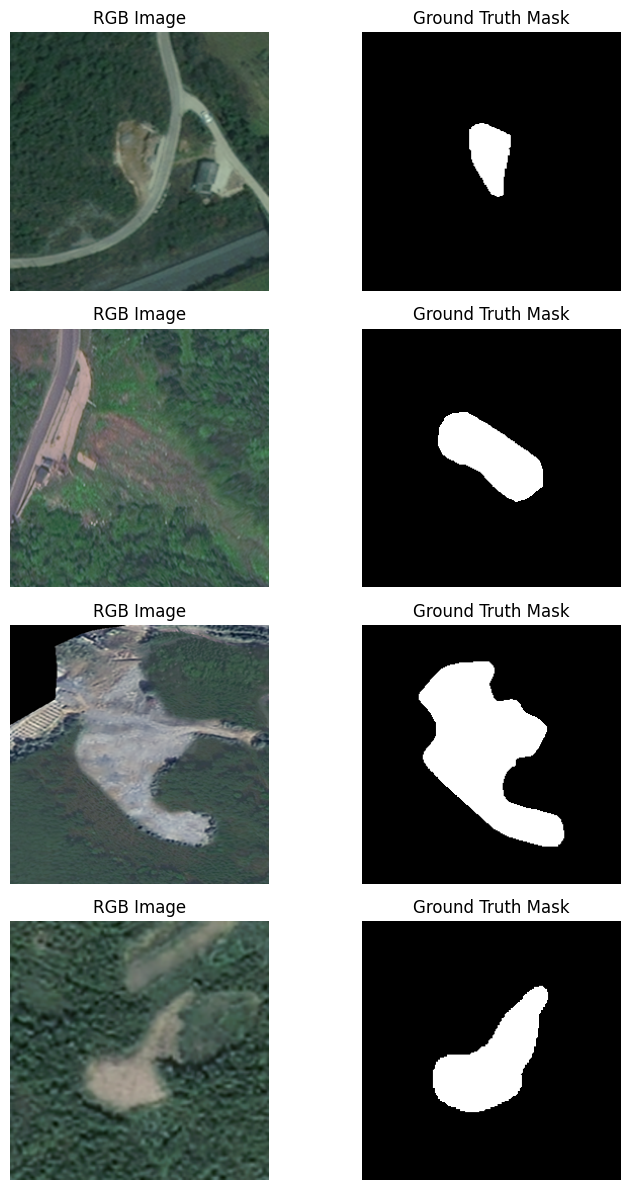

In [ ]:
images, masks = next(iter(train_loader))

fig, axes = plt.subplots(4, 2, figsize=(8, 12))

for i in range(4):

    axes[i, 0].imshow(images[i].permute(1, 2, 0))
    axes[i, 0].set_title("RGB Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

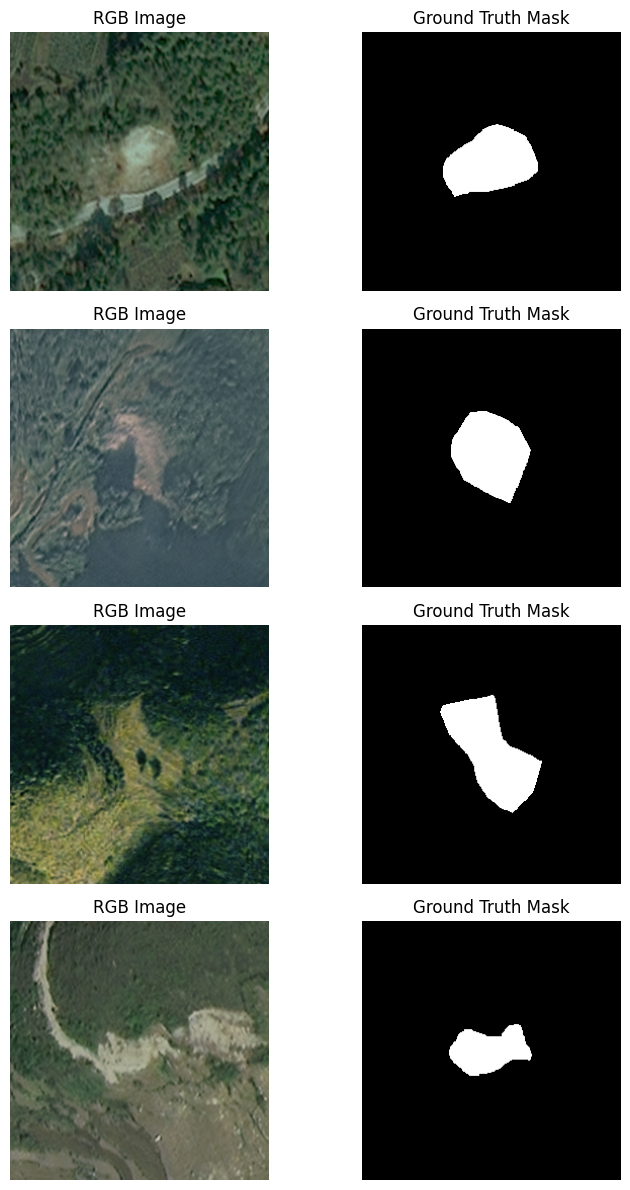

In [ ]:
images, masks = next(iter(train_loader))

fig, axes = plt.subplots(4, 2, figsize=(8, 12))

for i in range(4):

    axes[i, 0].imshow(images[i].permute(1, 2, 0))
    axes[i, 0].set_title("RGB Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class CustomLandslideCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(

            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.decoder = nn.Sequential(

            nn.ConvTranspose2d(
                64, 32, 2, stride=2
            ),

            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 32, 2, stride=2
            ),

            nn.ReLU(),

            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):

        x = self.encoder(x)

        x = self.decoder(x)

        return x

In [ ]:
class UNetBaseline(nn.Module):

    def __init__(self):
        super().__init__()

        self.down1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU()
        )

        self.pool1 = nn.MaxPool2d(2)

        self.down2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU()
        )

        self.pool2 = nn.MaxPool2d(2)

        self.bottleneck = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU()
        )

        self.up1 = nn.ConvTranspose2d(
            128, 64, 2, stride=2
        )

        self.conv_up1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU()
        )

        self.up2 = nn.ConvTranspose2d(
            64, 32, 2, stride=2
        )

        self.conv_up2 = nn.Sequential(
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU()
        )

        self.final_conv = nn.Conv2d(32, 1, 1)

    def forward(self, x):

        d1 = self.down1(x)

        x = self.pool1(d1)

        d2 = self.down2(x)

        x = self.pool2(d2)

        x = self.bottleneck(x)

        x = self.up1(x)

        x = torch.cat([x, d2], dim=1)

        x = self.conv_up1(x)

        x = self.up2(x)

        x = torch.cat([x, d1], dim=1)

        x = self.conv_up2(x)

        return self.final_conv(x)

In [ ]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):
        super().__init__()

        self.smooth = smooth

    def forward(self, inputs, targets):

        inputs = torch.sigmoid(inputs)

        inputs = inputs.view(-1)
        targets = targets.view(-1)

        intersection = (inputs * targets).sum()

        dice = (
            2 * intersection + self.smooth
        ) / (
            inputs.sum() +
            targets.sum() +
            self.smooth
        )

        return 1 - dice

In [ ]:
class BCEDiceLoss(nn.Module):

    def __init__(self):

        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, inputs, targets):

        bce_loss = self.bce(
            inputs,
            targets
        )

        inputs_sigmoid = torch.sigmoid(inputs)

        inputs_flat = inputs_sigmoid.view(-1)
        targets_flat = targets.view(-1)

        intersection = (
            inputs_flat * targets_flat
        ).sum()

        dice_loss = 1 - (
            2 * intersection + 1e-6
        ) / (
            inputs_flat.sum()
            + targets_flat.sum()
            + 1e-6
        )

        return bce_loss + dice_loss

In [ ]:
# CELL 25 — Models + Losses + Training Utilities

import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)


# =========================
# 1. CUSTOM CNN
# =========================

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 2, stride=2),
            nn.ReLU(),

            nn.Conv2d(32, 1, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# =========================
# 2. U-NET
# =========================

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(3, 64)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(64, 128)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(128, 256)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, 1, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)


# =========================
# 3. DICE LOSS
# =========================

class DiceLoss(nn.Module):
    def forward(self, inputs, targets):

        inputs = torch.sigmoid(inputs)

        inputs = inputs.view(-1)
        targets = targets.view(-1)

        intersection = (inputs * targets).sum()

        dice = (2 * intersection + 1e-7) / (
            inputs.sum() + targets.sum() + 1e-7
        )

        return 1 - dice


class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(15.0).to(DEVICE)
        )

        self.dice = DiceLoss()

    def forward(self, inputs, targets):
        return self.bce(inputs, targets) + self.dice(inputs, targets)


# BCE loss used by the original models
bce_loss = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(15.0).to(DEVICE)
)


# =========================
# 4. METRICS
# =========================

def calculate_metrics(model, loader):

    model.eval()

    TP = TN = FP = FN = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = model(images)

            preds = (torch.sigmoid(outputs) > 0.5).float()

            TP += ((preds == 1) & (masks == 1)).sum().item()
            TN += ((preds == 0) & (masks == 0)).sum().item()
            FP += ((preds == 1) & (masks == 0)).sum().item()
            FN += ((preds == 0) & (masks == 1)).sum().item()

    precision = TP / (TP + FP + 1e-8)

    recall = TP / (TP + FN + 1e-8)

    f1 = 2 * precision * recall / (
        precision + recall + 1e-8
    )

    iou = TP / (
        TP + FP + FN + 1e-8
    )

    pixel_accuracy = (
        TP + TN
    ) / (
        TP + TN + FP + FN + 1e-8
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou,
        "Pixel Accuracy": pixel_accuracy
    }


# =========================
# 5. TRAINING FUNCTION
# =========================

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    epochs,
    lr,
    save_path,
    patience=5
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    best_iou = 0
    best_weights = copy.deepcopy(
        model.state_dict()
    )

    wait = 0

    for epoch in range(epochs):

        model.train()

        running_loss = 0

        for images, masks in train_loader:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                masks
            )

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        metrics = calculate_metrics(
            model,
            val_loader
        )

        avg_loss = (
            running_loss /
            len(train_loader)
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {avg_loss:.4f} | "
            f"IoU: {metrics['IoU']:.4f}"
        )

        if metrics["IoU"] > best_iou:

            best_iou = metrics["IoU"]

            best_weights = copy.deepcopy(
                model.state_dict()
            )

            torch.save(
                best_weights,
                save_path
            )

            wait = 0

        else:

            wait += 1

        if wait >= patience:

            print("Early stopping.")

            break

    model.load_state_dict(
        best_weights
    )

    return model


print("Models, losses, metrics and training function are ready.")

Using device: cuda
Models, losses, metrics and training function are ready.


In [ ]:
# Model 1: Custom CNN
m1 = CustomCNN().to(DEVICE)

m1 = train_model(
    m1,
    train_loader,
    val_loader,
    criterion=bce_loss,
    epochs=10,
    lr=0.001,
    save_path=f"{SAVE_DIR}/M1_custom_cnn.pth",
    patience=5
)

# Model 2: Plain U-Net
m2 = UNet().to(DEVICE)

m2 = train_model(
    m2,
    train_loader,
    val_loader,
    criterion=bce_loss,
    epochs=10,
    lr=0.001,
    save_path=f"{SAVE_DIR}/M2_unet.pth",
    patience=5
)

print("M1 and M2 training completed.")

Epoch 1/10 | Loss: 1.3577 | IoU: 0.2735
Epoch 2/10 | Loss: 1.1608 | IoU: 0.1836
Epoch 3/10 | Loss: 1.1197 | IoU: 0.1942
Epoch 4/10 | Loss: 1.1124 | IoU: 0.2195
Epoch 5/10 | Loss: 1.0693 | IoU: 0.2483
Epoch 6/10 | Loss: 1.0554 | IoU: 0.2772
Epoch 7/10 | Loss: 1.0829 | IoU: 0.2746
Epoch 8/10 | Loss: 1.0471 | IoU: 0.2599
Epoch 9/10 | Loss: 1.0355 | IoU: 0.1919
Epoch 10/10 | Loss: 1.0155 | IoU: 0.1745
Epoch 1/10 | Loss: 1.4036 | IoU: 0.2511
Epoch 2/10 | Loss: 1.1620 | IoU: 0.2338
Epoch 3/10 | Loss: 1.1365 | IoU: 0.2549
Epoch 4/10 | Loss: 1.1130 | IoU: 0.2559
Epoch 5/10 | Loss: 1.5358 | IoU: 0.1635
Epoch 6/10 | Loss: 1.1409 | IoU: 0.2616
Epoch 7/10 | Loss: 1.1224 | IoU: 0.1977
Epoch 8/10 | Loss: 1.2196 | IoU: 0.2318
Epoch 9/10 | Loss: 1.1586 | IoU: 0.2145
Epoch 10/10 | Loss: 1.1452 | IoU: 0.1746
M1 and M2 training completed.


In [ ]:
# CELL 27 — M3: U-Net + Dice Loss + Augmentation

# Find image and mask folders again
base_dir = "/content/bijie_data/Bijie-landslide-dataset"

image_dir = None
mask_dir = None

for root, dirs, files in os.walk(base_dir):

    png_files = [
        f for f in files
        if f.lower().endswith(".png")
    ]

    if len(png_files) == 0:
        continue

    folder_name = os.path.basename(root).lower()

    if "mask" in folder_name:
        mask_dir = root

    elif "image" in folder_name or "img" in folder_name:
        image_dir = root


print("Image directory:", image_dir)
print("Mask directory:", mask_dir)


# -------------------------
# Augmented dataset
# -------------------------

class AugmentedBijieDataset(Dataset):

    def __init__(self, image_dir, mask_dir, augment=False):

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.augment = augment

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".png")
        ])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_name = self.images[idx]

        image = Image.open(
            os.path.join(self.image_dir, img_name)
        ).convert("RGB")

        mask = Image.open(
            os.path.join(self.mask_dir, img_name)
        ).convert("L")

        image = image.resize((256, 256))
        mask = mask.resize((256, 256))

        image = np.array(image)
        mask = np.array(mask)

        # Random horizontal flip
        if self.augment and random.random() > 0.5:
            image = np.fliplr(image).copy()
            mask = np.fliplr(mask).copy()

        # Random vertical flip
        if self.augment and random.random() > 0.5:
            image = np.flipud(image).copy()
            mask = np.flipud(mask).copy()

        image = torch.tensor(
            image,
            dtype=torch.float32
        ).permute(2, 0, 1) / 255.0

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0) / 255.0

        mask = (mask > 0.5).float()

        return image, mask


# -------------------------
# Training data
# -------------------------

aug_dataset = AugmentedBijieDataset(
    image_dir,
    mask_dir,
    augment=True
)

train_aug = torch.utils.data.Subset(
    aug_dataset,
    train_indices
)

train_aug_loader = DataLoader(
    train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)


# -------------------------
# Clean validation data
# -------------------------

val_clean_dataset = AugmentedBijieDataset(
    image_dir,
    mask_dir,
    augment=False
)

val_clean = torch.utils.data.Subset(
    val_clean_dataset,
    val_indices
)

val_clean_loader = DataLoader(
    val_clean,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)


# -------------------------
# Train M3
# -------------------------

m3 = UNet().to(DEVICE)

m3 = train_model(
    m3,
    train_aug_loader,
    val_clean_loader,
    criterion=BCEDiceLoss(),
    epochs=50,
    lr=0.001,
    save_path=f"{SAVE_DIR}/M3_unet_dice_aug.pth",
    patience=10
)

print("M3 training completed.")

Image directory: /content/bijie_data/Bijie-landslide-dataset/landslide/image
Mask directory: /content/bijie_data/Bijie-landslide-dataset/landslide/mask
Epoch 1/50 | Loss: 2.0689 | IoU: 0.2875
Epoch 2/50 | Loss: 1.9092 | IoU: 0.2547
Epoch 3/50 | Loss: 1.8356 | IoU: 0.2698
Epoch 4/50 | Loss: 1.8458 | IoU: 0.2177
Epoch 5/50 | Loss: 1.8556 | IoU: 0.2698
Epoch 6/50 | Loss: 1.8383 | IoU: 0.1825
Epoch 7/50 | Loss: 2.0836 | IoU: 0.2350
Epoch 8/50 | Loss: 1.8931 | IoU: 0.2602
Epoch 9/50 | Loss: 1.8548 | IoU: 0.1877
Epoch 10/50 | Loss: 1.8837 | IoU: 0.2310
Epoch 11/50 | Loss: 2.1133 | IoU: 0.2531
Early stopping.
M3 training completed.


In [ ]:
!pip -q install segmentation-models-pytorch

import segmentation_models_pytorch as smp

m4 = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
).to(DEVICE)

m4 = train_model(
    m4,
    train_loader,
    val_loader,
    criterion=BCEDiceLoss(),
    epochs=50,
    lr=0.0005,
    save_path=f"{SAVE_DIR}/M4_resnet34_unet.pth",
    patience=10
)

print("M4 training completed.")

Epoch 1/50 | Loss: 1.3645 | IoU: 0.4314
Epoch 2/50 | Loss: 0.9302 | IoU: 0.5220
Epoch 3/50 | Loss: 0.7501 | IoU: 0.4359
Epoch 4/50 | Loss: 0.6775 | IoU: 0.4991
Epoch 5/50 | Loss: 0.5474 | IoU: 0.5839
Epoch 6/50 | Loss: 0.5000 | IoU: 0.6967
Epoch 7/50 | Loss: 0.4686 | IoU: 0.6778
Epoch 8/50 | Loss: 0.4225 | IoU: 0.6232
Epoch 9/50 | Loss: 0.4390 | IoU: 0.7234
Epoch 10/50 | Loss: 0.4649 | IoU: 0.5739
Epoch 11/50 | Loss: 0.4958 | IoU: 0.6990
Epoch 12/50 | Loss: 0.3656 | IoU: 0.6867
Epoch 13/50 | Loss: 0.3647 | IoU: 0.7077
Epoch 14/50 | Loss: 0.3348 | IoU: 0.6759
Epoch 15/50 | Loss: 0.2737 | IoU: 0.7561
Epoch 16/50 | Loss: 0.2455 | IoU: 0.7288
Epoch 17/50 | Loss: 0.2348 | IoU: 0.6842
Epoch 18/50 | Loss: 0.2168 | IoU: 0.7374
Epoch 19/50 | Loss: 0.1914 | IoU: 0.7517
Epoch 20/50 | Loss: 0.1853 | IoU: 0.7225
Epoch 21/50 | Loss: 0.1738 | IoU: 0.7381
Epoch 22/50 | Loss: 0.1580 | IoU: 0.7427
Epoch 23/50 | Loss: 0.1551 | IoU: 0.7523
Epoch 24/50 | Loss: 0.2026 | IoU: 0.7304
Epoch 25/50 | Loss: 0.174

In [ ]:
models = {
    "Custom CNN": m1,
    "U-Net": m2,
    "U-Net + Dice + Aug": m3,
    "ResNet34 U-Net": m4
}

results = {}

for name, model in models.items():
    loader = val_clean_loader if name == "U-Net + Dice + Aug" else val_loader
    results[name] = calculate_metrics(model, loader)

results_df = pd.DataFrame(results).T

print(results_df.round(4))

                    Precision  Recall      F1     IoU  Pixel Accuracy
Custom CNN             0.2889  0.8731  0.4341  0.2772          0.7515
U-Net                  0.2735  0.8574  0.4147  0.2616          0.7358
U-Net + Dice + Aug     0.3240  0.7188  0.4466  0.2875          0.8056
ResNet34 U-Net         0.8320  0.8924  0.8611  0.7561          0.9686


In [ ]:
results_df.to_csv(
    f"{SAVE_DIR}/phase1_results.csv"
)

print(f"Results saved to: {SAVE_DIR}/phase1_results.csv")

Results saved to: /content/drive/MyDrive/TerraSeg/phase1/phase1_results.csv


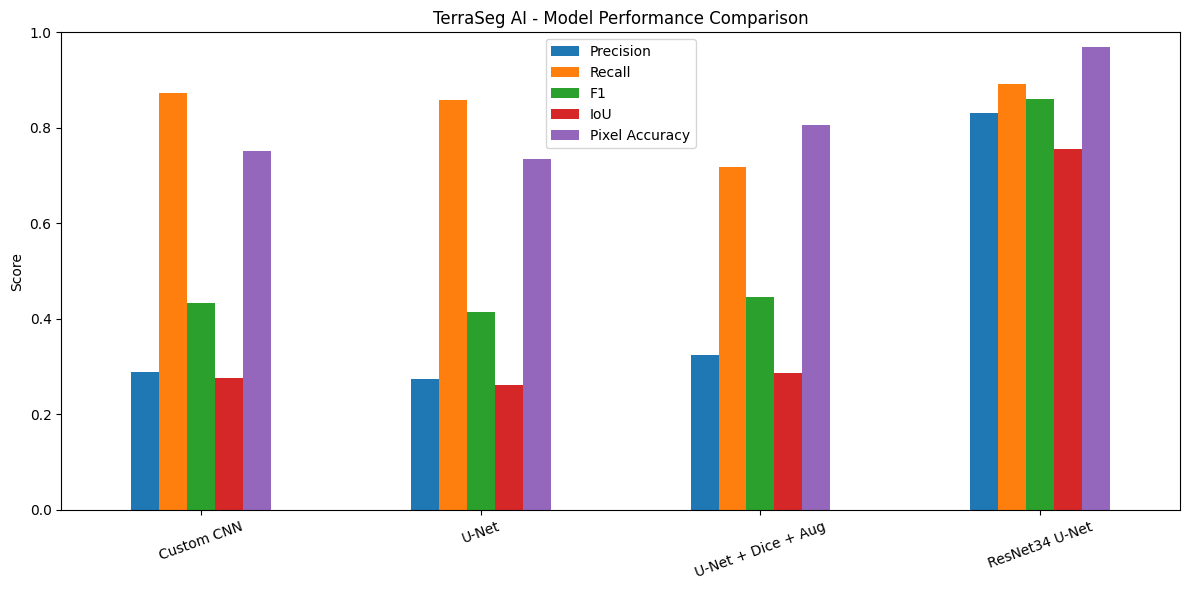

In [ ]:
results_df[["Precision", "Recall", "F1", "IoU", "Pixel Accuracy"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("TerraSeg AI - Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

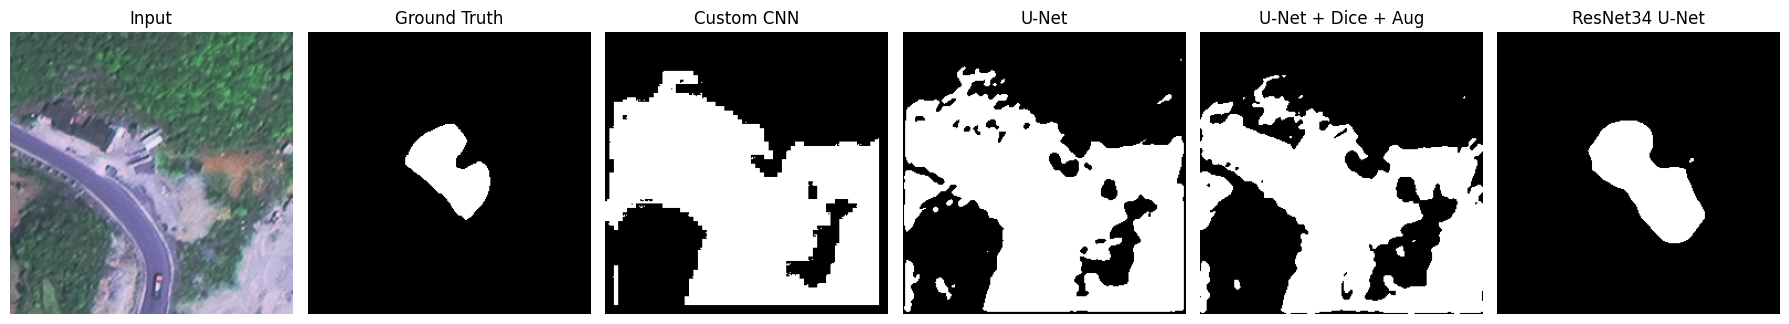

In [ ]:
image, mask = val_clean_dataset[val_indices[0]]

image_input = image.unsqueeze(0).to(DEVICE)

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

axes[0].imshow(image.permute(1, 2, 0))
axes[0].set_title("Input")

axes[1].imshow(mask.squeeze(), cmap="gray")
axes[1].set_title("Ground Truth")

for i, (name, model) in enumerate(models.items()):
    model.eval()

    with torch.no_grad():
        prediction = torch.sigmoid(
            model(image_input)
        )[0, 0].cpu().numpy()

    prediction = prediction > 0.5

    axes[i + 2].imshow(prediction, cmap="gray")
    axes[i + 2].set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os, time, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

OUT_DIR = '/content'          # CSV and figures are saved here. Change to a Drive path if you want.
IMG_SIZE = 256

print("Models found      :", list(models.keys()))
print("Train images      :", len(train_loader.dataset))
print("Validation images :", len(val_loader.dataset))
print("Val loader shuffles:", type(val_loader.sampler).__name__ == 'RandomSampler')  # must be False

# If the validation set comes from the AUGMENTED dataset, images get randomly flipped on every pass.
# Scores then change slightly each run. Fine for now, but note it in your report.
base = val_loader.dataset.dataset if hasattr(val_loader.dataset, 'dataset') else val_loader.dataset
print("Validation set uses augmentation:", type(base).__name__)


Models found      : ['Custom CNN', 'U-Net', 'U-Net + Dice + Aug', 'ResNet34 U-Net']
Train images      : 616
Validation images : 154
Val loader shuffles: False
Validation set uses augmentation: BijieDataset


In [ ]:

# ---------------------------------------------------------------------
# CELL 1 (OPTIONAL) - ablation: is it the ResNet backbone or the loss?
# Trains the plain U-Net with the SAME BCE+Dice loss that ResNet34 used.
#   If it stays low  -> the pretrained backbone is the hero.
#   If it jumps up   -> the loss function deserves part of the credit.
# Needs UNetBaseline and BCEDiceLoss from your earlier cells. Takes a few minutes.
# Set RUN_ABLATION = False to skip.
# ---------------------------------------------------------------------
RUN_ABLATION = True

if RUN_ABLATION:
    import torch.optim as optim
    abl_name = "U-Net + BCE+Dice (ablation)"
    abl_path = os.path.join(OUT_DIR, 'unet_bcedice_ablation.pth')

    abl_model = UNetBaseline().to(device)
    abl_criterion = BCEDiceLoss()
    abl_opt = optim.Adam(abl_model.parameters(), lr=1e-3)

    best, bad, patience = float('inf'), 0, 10
    for epoch in range(50):
        abl_model.train()
        tr = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            abl_opt.zero_grad()
            loss = abl_criterion(abl_model(x), y)
            loss.backward()
            abl_opt.step()
            tr += loss.item()
        abl_model.eval()
        va = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                va += abl_criterion(abl_model(x.to(device)), y.to(device)).item()
        tr, va = tr / len(train_loader), va / len(val_loader)
        print(f"Epoch {epoch+1}/50 | train {tr:.4f} | val {va:.4f}")
        if va < best:
            best, bad = va, 0
            torch.save(abl_model.state_dict(), abl_path)
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping")
                break

    abl_model.load_state_dict(torch.load(abl_path, map_location=device))
    models[abl_name] = abl_model
    print("Added to models dict:", abl_name)


Epoch 1/50 | train 2.1457 | val 2.1106
Epoch 2/50 | train 1.9138 | val 1.8750
Epoch 3/50 | train 1.9565 | val 1.8532
Epoch 4/50 | train 1.8963 | val 1.9042
Epoch 5/50 | train 1.8623 | val 1.8562
Epoch 6/50 | train 1.8312 | val 1.7133
Epoch 7/50 | train 1.7674 | val 1.6349
Epoch 8/50 | train 1.7548 | val 1.6419
Epoch 9/50 | train 1.7366 | val 1.6720
Epoch 10/50 | train 1.7409 | val 1.6989
Epoch 11/50 | train 1.7457 | val 1.7420
Epoch 12/50 | train 1.7627 | val 2.0853
Epoch 13/50 | train 1.7237 | val 1.6616
Epoch 14/50 | train 1.7170 | val 1.5840
Epoch 15/50 | train 1.7202 | val 1.6692
Epoch 16/50 | train 1.7283 | val 1.6073
Epoch 17/50 | train 1.6445 | val 1.5434
Epoch 18/50 | train 1.8964 | val 1.7857
Epoch 19/50 | train 1.8155 | val 1.8252
Epoch 20/50 | train 1.7499 | val 1.8185
Epoch 21/50 | train 1.7507 | val 1.6840
Epoch 22/50 | train 1.7159 | val 1.8937
Epoch 23/50 | train 1.8113 | val 1.6646
Epoch 24/50 | train 1.7294 | val 1.8999
Epoch 25/50 | train 1.7741 | val 1.6657
Epoch 26/

In [ ]:
def metrics_from_counts(tp, fp, fn, tn):
    eps = 1e-9
    return {
        'Precision':      tp / (tp + fp + eps),
        'Recall':         tp / (tp + fn + eps),
        'F1':             2 * tp / (2 * tp + fp + fn + eps),
        'IoU':            tp / (tp + fp + fn + eps),
        'Pixel Accuracy': (tp + tn) / (tp + tn + fp + fn + eps),
    }


@torch.no_grad()
def evaluate_full(model, loader, threshold=0.5):
    # counts TP/FP/FN/TN over the WHOLE validation set, then computes the metrics once
    model.eval()
    tp = fp = fn = tn = 0.0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        preds = (torch.sigmoid(model(images)) > threshold).float()
        tp += (preds * masks).sum().item()
        fp += (preds * (1 - masks)).sum().item()
        fn += ((1 - preds) * masks).sum().item()
        tn += ((1 - preds) * (1 - masks)).sum().item()
    return metrics_from_counts(tp, fp, fn, tn)


@torch.no_grad()
def measure_speed(model, batch_size=1, n_warmup=10, n_runs=100):
    # synchronize() makes sure the GPU has really finished before we stop the clock
    model.eval()
    x = torch.randn(batch_size, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(n_warmup):
        model(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(n_runs):
        model(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    total = time.time() - start
    return n_runs * batch_size / total, total / (n_runs * batch_size) * 1000   # FPS, ms per image


results = []
for name, model in models.items():
    model = model.to(device).eval()
    m = evaluate_full(model, val_loader)
    fps1, lat1 = measure_speed(model, batch_size=1)
    fps8, _ = measure_speed(model, batch_size=8)
    row = {'Model': name, **m,
           'Params (M)': sum(p.numel() for p in model.parameters()) / 1e6,
           'FPS (batch=1)': fps1, 'FPS (batch=8)': fps8, 'Latency (ms/img)': lat1}
    results.append(row)
    print(f"{name:32s} IoU {m['IoU']:.3f} | F1 {m['F1']:.3f} | {fps1:.0f} FPS | {row['Params (M)']:.2f} M params")


Custom CNN                       IoU 0.277 | F1 0.434 | 598 FPS | 0.13 M params
U-Net                            IoU 0.262 | F1 0.415 | 30 FPS | 7.70 M params
U-Net + Dice + Aug               IoU 0.288 | F1 0.447 | 30 FPS | 7.70 M params
ResNet34 U-Net                   IoU 0.756 | F1 0.861 | 79 FPS | 24.44 M params
U-Net + BCE+Dice (ablation)      IoU 0.269 | F1 0.425 | 121 FPS | 0.47 M params


In [ ]:

# ---------------------------------------------------------------------
# CELL 3 - Random Forest baseline (classical machine learning)
# Each pixel becomes 11 numbers (colour, local brightness/texture, edge strength)
# and the forest classifies every pixel on its own - it has no idea of "shape".
# Takes a few minutes (the prediction over all validation pixels is the slow part).
# ---------------------------------------------------------------------
from sklearn.ensemble import RandomForestClassifier
from scipy.ndimage import uniform_filter, sobel
from skimage.color import rgb2hsv, rgb2gray

N_FEATS = 11
SEED = 42


def extract_pixel_features(img):
    # img: H x W x 3 array in [0,1]  ->  H x W x 11 feature array
    hsv = rgb2hsv(img)
    gray = rgb2gray(img)
    feats = [img[..., 0], img[..., 1], img[..., 2], hsv[..., 0], hsv[..., 1], hsv[..., 2]]
    for k in (5, 15):
        mean = uniform_filter(gray, k)
        sq_mean = uniform_filter(gray ** 2, k)
        feats += [mean, np.sqrt(np.clip(sq_mean - mean ** 2, 0, None))]   # local mean + local texture
    feats.append(np.hypot(sobel(gray, axis=1), sobel(gray, axis=0)))      # edge strength
    return np.stack(feats, axis=-1).astype(np.float32)


def to_numpy(sample):
    img, mask = sample
    return img.permute(1, 2, 0).numpy(), (mask[0].numpy() > 0.5).astype(np.uint8)


train_ds, val_ds = train_loader.dataset, val_loader.dataset
rng = np.random.default_rng(SEED)
PIX_PER_IMAGE = 500          # sample 500 random pixels per training image (all pixels would be too slow)

Xs, ys = [], []
for i in range(len(train_ds)):
    img, mask = to_numpy(train_ds[i])
    f = extract_pixel_features(img).reshape(-1, N_FEATS)
    y = mask.reshape(-1)
    sel = rng.choice(len(y), PIX_PER_IMAGE, replace=False)
    Xs.append(f[sel]); ys.append(y[sel])
X_train, y_train = np.concatenate(Xs), np.concatenate(ys)
print(f"RF training table: {len(y_train)} pixels, {y_train.mean()*100:.1f}% landslide")

rf = RandomForestClassifier(n_estimators=50, max_depth=14, min_samples_leaf=20,
                            class_weight='balanced_subsample', n_jobs=-1, random_state=SEED)
t0 = time.time()
rf.fit(X_train, y_train)
print(f"RF trained in {time.time()-t0:.1f}s")

# evaluate on the validation images with the same metrics
tp = fp = fn = tn = 0
t0 = time.time()
for i in range(len(val_ds)):
    img, mask = to_numpy(val_ds[i])
    pred = rf.predict(extract_pixel_features(img).reshape(-1, N_FEATS)).reshape(mask.shape)
    p, t = pred == 1, mask == 1
    tp += (p & t).sum(); fp += (p & ~t).sum(); fn += (~p & t).sum(); tn += (~p & ~t).sum()
elapsed = time.time() - t0

m = metrics_from_counts(float(tp), float(fp), float(fn), float(tn))
results.append({'Model': 'Random Forest (classical ML)', **m,
                'Params (M)': float('nan'),
                'FPS (batch=1)': len(val_ds) / elapsed, 'FPS (batch=8)': float('nan'),
                'Latency (ms/img)': elapsed / len(val_ds) * 1000})     # CPU, includes feature extraction
print(f"Random Forest -> IoU {m['IoU']:.3f} | F1 {m['F1']:.3f} | P {m['Precision']:.3f} | R {m['Recall']:.3f}")

RF training table: 308000 pixels, 9.9% landslide
RF trained in 45.8s
Random Forest -> IoU 0.291 | F1 0.451 | P 0.321 | R 0.761


,Precision,Recall,F1,IoU,Pixel Accuracy,Params (M),FPS (batch=1),FPS (batch=8),Latency (ms/img)
Model,,,,,,,,,
Custom CNN,0.2889,0.8731,0.4341,0.2772,0.7515,0.1343,598.0150,689.8494,1.6722
U-Net,0.2735,0.8574,0.4147,0.2616,0.7358,7.6973,29.6815,50.9092,33.6910
U-Net + Dice + Aug,0.3240,0.7188,0.4466,0.2875,0.8056,7.6973,29.7601,50.9351,33.6020
ResNet34 U-Net,0.8320,0.8924,0.8611,0.7561,0.9686,24.4364,79.2203,153.7390,12.6230
U-Net + BCE+Dice (ablation),0.2757,0.9224,0.4246,0.2695,0.7271,0.4665,120.8789,153.3384,8.2727
Random Forest (classical ML),0.3208,0.7612,0.4514,0.2915,0.7980,NaN,4.2052,NaN,237.8027



Best model by F1: ResNet34 U-Net (IoU 0.756)


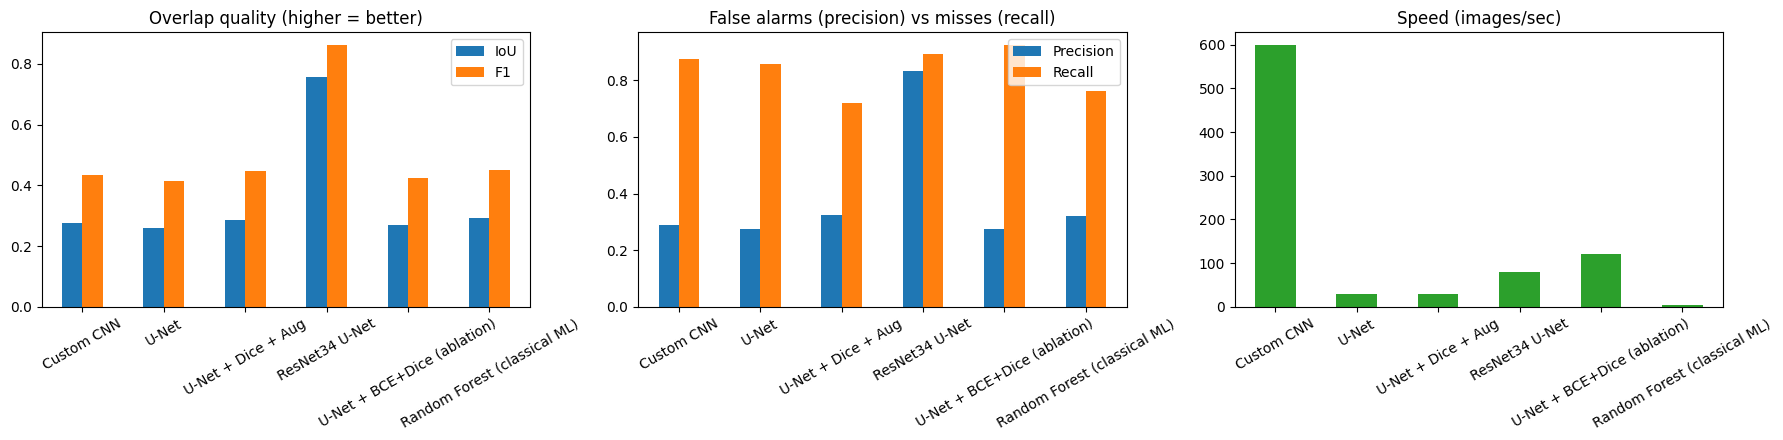

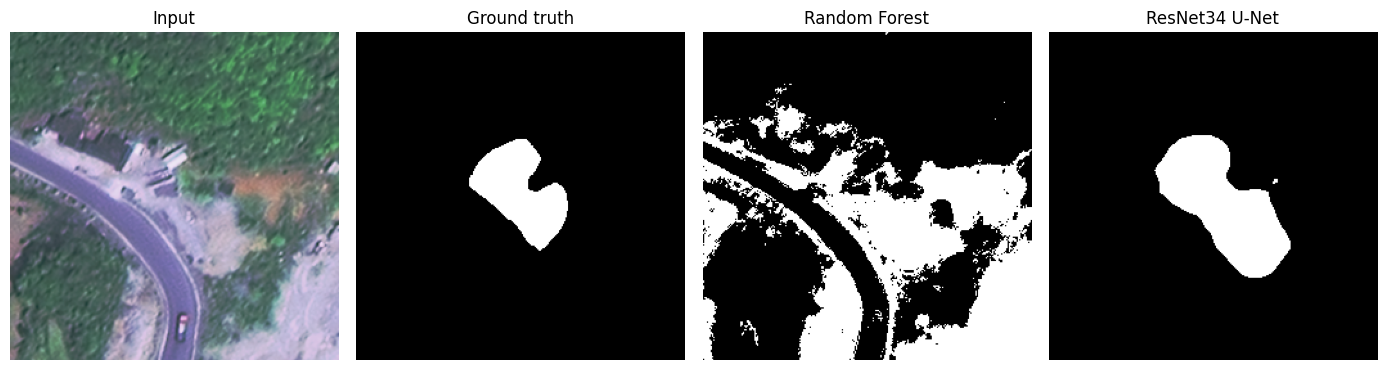

Saved to /content -> download phase1_results_full.csv and the PNGs from the Colab file panel


In [ ]:

# ---------------------------------------------------------------------
# CELL 4 - final Phase 1 table + charts + RF prediction picture
# ---------------------------------------------------------------------
df = pd.DataFrame(results).set_index('Model')
df_show = df.round(4)
df_show.to_csv(os.path.join(OUT_DIR, 'phase1_results_full.csv'))
display(df_show)
best = df['F1'].idxmax()
print(f"\nBest model by F1: {best} (IoU {df.loc[best, 'IoU']:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
df[['IoU', 'F1']].plot(kind='bar', ax=axes[0], rot=30);            axes[0].set_title("Overlap quality (higher = better)")
df[['Precision', 'Recall']].plot(kind='bar', ax=axes[1], rot=30);  axes[1].set_title("False alarms (precision) vs misses (recall)")
df['FPS (batch=1)'].plot(kind='bar', ax=axes[2], rot=30, color='tab:green'); axes[2].set_title("Speed (images/sec)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'phase1_charts.png'), dpi=150)
plt.show()

# same validation image, Random Forest next to the best deep model
img_t, mask_t = val_ds[0]
img_np = img_t.permute(1, 2, 0).numpy()
rf_pred = rf.predict(extract_pixel_features(img_np).reshape(-1, N_FEATS)).reshape(IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    best_dl = [n for n in models if n in df.index][-1] if 'ResNet34 U-Net' not in models else 'ResNet34 U-Net'
    dl_pred = (torch.sigmoid(models[best_dl].eval()(img_t.unsqueeze(0).to(device)))[0, 0] > 0.5).cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (title, im, cmap) in zip(axes, [("Input", img_np, None), ("Ground truth", mask_t[0].numpy(), 'gray'),
                                        ("Random Forest", rf_pred, 'gray'), (best_dl, dl_pred, 'gray')]):
    ax.imshow(im, cmap=cmap); ax.set_title(title); ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'phase1_rf_vs_dl.png'), dpi=150)
plt.show()
print("Saved to", OUT_DIR, "-> download phase1_results_full.csv and the PNGs from the Colab file panel")